# Handwritten Digit Classifier

Recognising handwritten digits (0–9) from images with a convolutional neural network.
This notebook runs every stage the deployed API uses, with the same code from `src/`:

1. Data acquisition
2. Exploring the data: features and what they tell us
3. Preprocessing
4. Model creation
5. Training
6. Model testing with the full set of metrics
7. Prediction functions
8. Retraining on newly uploaded data

**Dataset:** 1,797 real handwritten digits from the UCI / scikit-learn digits dataset, recorded at 8×8 pixels
and stored as 64×64 grayscale PNGs in `data/raw/train` (1,437) and `data/raw/test` (360).

In [1]:
import os, sys, random, io
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from PIL import Image

from src import config
from src import preprocessing as prep
from src import model as mdl

sns.set_theme(style="whitegrid")
tf.random.set_seed(config.SEED); np.random.seed(config.SEED); random.seed(config.SEED)
print("TensorFlow", tf.__version__)

2026-11-25 12:39:39.109722: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow 2.18.0


## 1. Data acquisition

`acquire_data()` uses the PNGs already in `data/raw/`. If that folder is empty it exports the same dataset
from scikit-learn (no download needed), with a stratified 80/20 train/test split. The test set is never used
for training or model selection.

In [2]:
counts = prep.acquire_data()
pd.DataFrame(counts).assign(total=lambda d: d.sum(axis=1))

Using existing images in data/raw
{'train': 1437, 'test': 360} images


,train,test,total
0,142,36,178
1,146,36,182
2,142,35,177
3,146,37,183
4,145,36,181
5,145,37,182
6,145,36,181
7,143,36,179
8,139,35,174
9,144,36,180


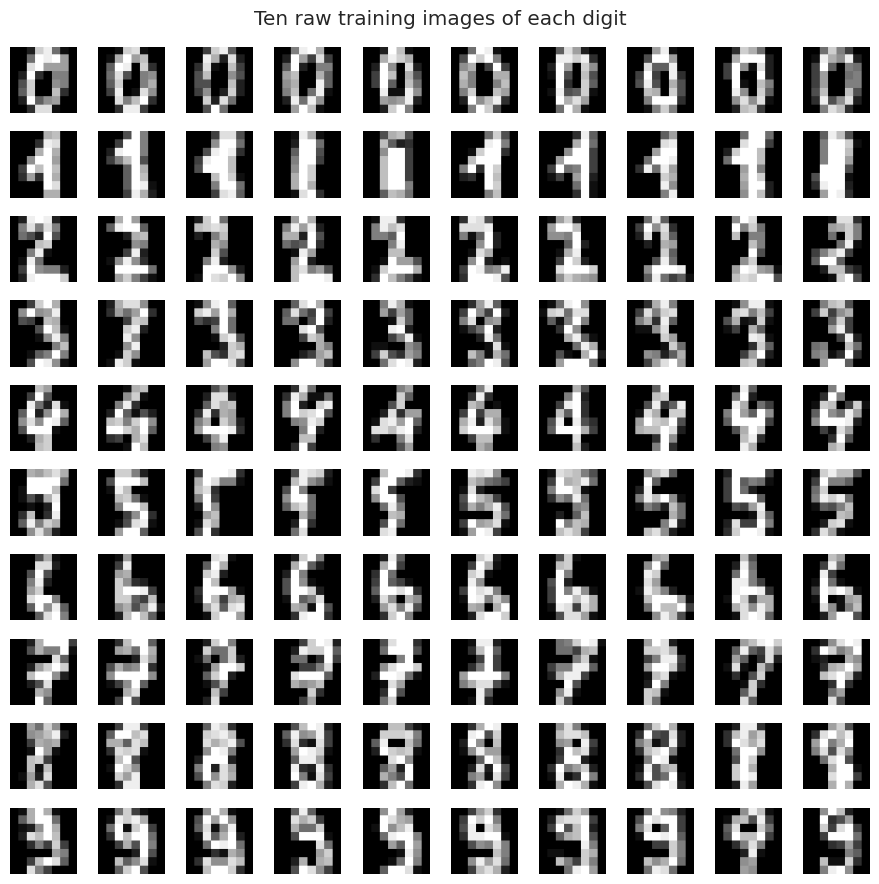

In [3]:
fig, axes = plt.subplots(10, 10, figsize=(9, 9))
for d in range(10):
    files = sorted((prep.RAW_DIR / "train" / str(d)).iterdir())[:10]
    for k, f in enumerate(files):
        axes[d, k].imshow(Image.open(f), cmap="gray"); axes[d, k].axis("off")
plt.suptitle("Ten raw training images of each digit"); plt.tight_layout(); plt.show()

## 2. Exploring the data

Images have no columns, so we measure features from each one (after preprocessing, see section 3):

| Feature | How it is computed | Why it matters |
|---|---|---|
| Class count | images per folder | imbalance would bias the model |
| Aspect ratio | width ÷ height of the digit's bounding box | some digits are naturally narrow |
| Ink coverage | share of pixels that are part of the stroke | how much "material" each digit has |
| Top-heaviness | share of ink in the top half | where the mass of the digit sits |
| Average image | mean of all images of a digit | how consistently people write it |

In [4]:
prep.process_dataset()        # explained in section 3; done here so features use the final format
feats = prep.dataset_features(config.TRAIN_DIR)
feats.groupby("label")[["aspect_ratio", "ink_coverage", "top_heaviness", "stroke_intensity"]].agg(["mean", "std"]).round(3)

aspect_ratio        ink_coverage        top_heaviness         \
              mean    std         mean    std          mean    std   
label                                                                
0            0.732  0.040        0.499  0.036         0.503  0.028   
1            0.610  0.121        0.428  0.047         0.511  0.073   
2            0.753  0.078        0.453  0.035         0.466  0.038   
3            0.704  0.069        0.454  0.037         0.518  0.043   
4            0.763  0.053        0.454  0.036         0.448  0.065   
5            0.714  0.062        0.454  0.037         0.567  0.047   
6            0.731  0.042        0.470  0.034         0.349  0.045   
7            0.707  0.055        0.452  0.035         0.580  0.059   
8            0.670  0.070        0.502  0.039         0.523  0.038   
9            0.717  0.054        0.485  0.039         0.590  0.055   

      stroke_intensity         
                  mean    std  
label                          
0                0.558  0.048  
1                0.664  0.056  
2                0.614  0.047  
3                0.592  0.050  
4                0.610  0.041  
5                0.595  0.047  
6                0.586  0.053  
7                0.591  0.042  
8                0.595  0.054  
9                0.573  0.047

### Feature 1: class distribution

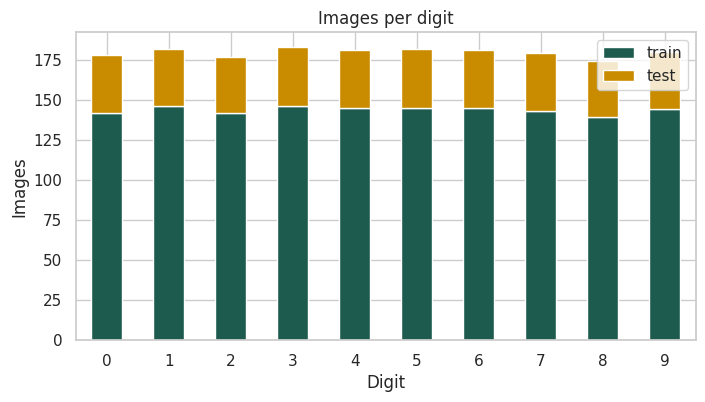

Largest / smallest class: 1.05


In [5]:
train_counts, test_counts = prep.class_counts(config.TRAIN_DIR), prep.class_counts(config.TEST_DIR)
ax = pd.DataFrame({"train": train_counts, "test": test_counts}).plot.bar(stacked=True, figsize=(8, 4), color=["#1E5B4F", "#C98C00"])
ax.set(xlabel="Digit", ylabel="Images", title="Images per digit"); plt.xticks(rotation=0); plt.show()
print(f"Largest / smallest class: {max(train_counts.values()) / min(train_counts.values()):.2f}")

**Interpretation.** Every digit has 141–146 training images, a ratio of about 1.04. The dataset is balanced,
so the model has no incentive to favour any digit, and plain accuracy is a fair headline metric. We still
report macro-averaged precision, recall and F1 so a weak digit cannot hide behind a good average.

### Feature 2: digit width (aspect ratio)

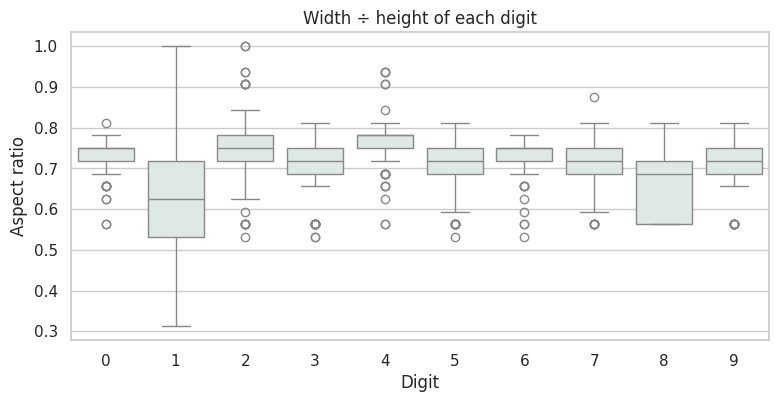

In [6]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=feats, x="label", y="aspect_ratio", color="#DCEAE5")
plt.title("Width ÷ height of each digit"); plt.xlabel("Digit"); plt.ylabel("Aspect ratio"); plt.show()

**Interpretation.** Digit 1 is the narrowest (median ≈ 0.63) and varies the most, because writers draw it anywhere from a thin stroke to a slanted, almost square shape. 8 is also fairly narrow. 4 and 2 are the widest (≈ 0.75–0.78). The other digits overlap around 0.72–0.75, so width alone can't separate them and the model has to learn their shapes. That is why a CNN fits this data


### Feature 3: ink coverage and top-heaviness

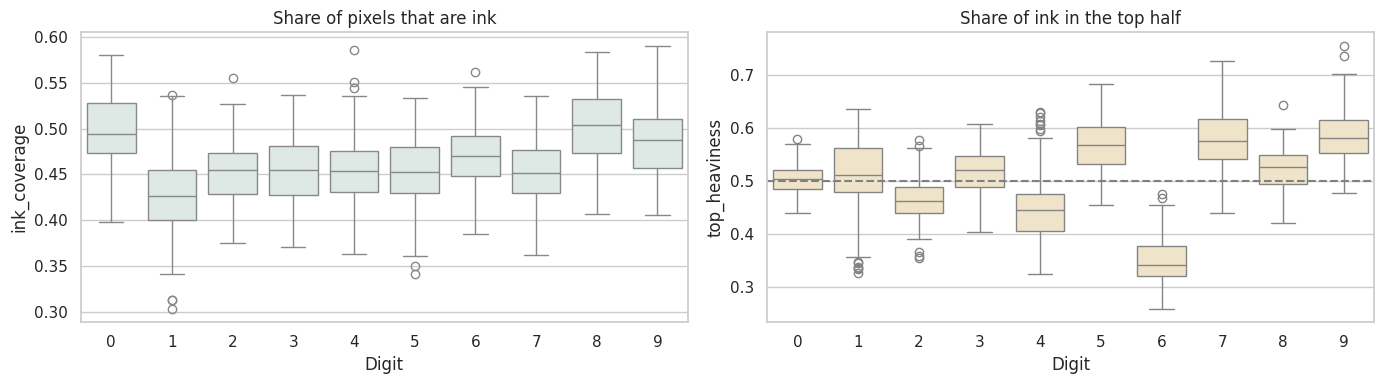

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=feats, x="label", y="ink_coverage", color="#DCEAE5", ax=ax[0])
ax[0].set(title="Share of pixels that are ink", xlabel="Digit")
sns.boxplot(data=feats, x="label", y="top_heaviness", color="#F5E6C4", ax=ax[1])
ax[1].axhline(0.5, color="grey", ls="--"); ax[1].set(title="Share of ink in the top half", xlabel="Digit")
plt.tight_layout(); plt.show()

**Interpretation.** Ink coverage is similar for every digit (about 43–50% of the image), with 1 using the least ink. So the amount of ink says little about which digit it is. Top-heaviness is more useful:

Top-heavy: 9, 7 and 5 carry most of their ink above the middle line.
Bottom-heavy: 6 is strongly bottom-heavy, because its loop sits low.
Balanced: 0, 1, 3 and 8 are close to even.

Digits on opposite sides of the line, like 6 and 9, are easy to tell apart. Digits on the same side, like 5 and 9 or 3 and 8, need finer shape detail, and that's where the model is most likely to make mistakes.



### Feature 4: the average digit

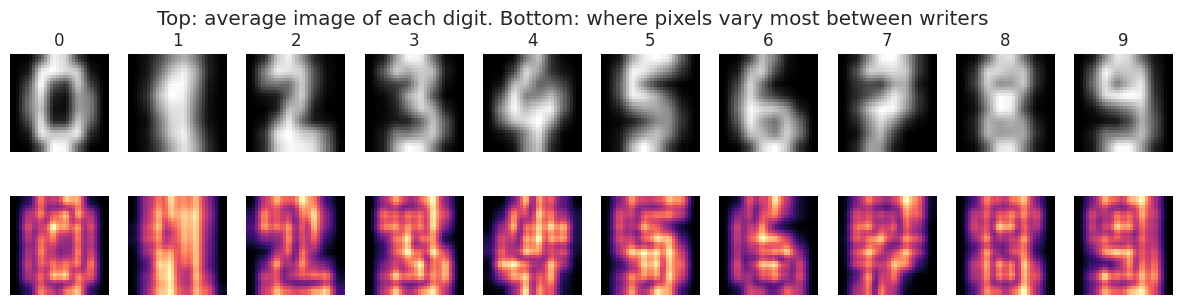

In [8]:
means = prep.mean_images(config.TRAIN_DIR, size=32)
fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
for d in range(10):
    m = np.array(means[str(d)])
    axes[0, d].imshow(m, cmap="gray"); axes[0, d].set_title(str(d)); axes[0, d].axis("off")
    stack = np.stack([np.asarray(Image.open(f), dtype=np.float32) / 255 for f in (config.TRAIN_DIR / str(d)).iterdir()])
    axes[1, d].imshow(stack.std(0), cmap="magma"); axes[1, d].axis("off")
axes[0, 0].set_ylabel("mean"); axes[1, 0].set_ylabel("std")
plt.suptitle("Top: average image of each digit. Bottom: where pixels vary most between writers"); plt.show()

**Interpretation.** The top row shows that most digits have a clear, recognisable average shape: 0, 2, 3, 5, 6, 8 and 9 look sharp, so people write them in a fairly consistent way. 1, 4 and 7 are the blurriest, which means they have the most writing styles:

1: some writers draw a straight line, others slant it or add a flag.
4: some close the top, others leave it open.
7: some add a crossbar, others don't.

The bottom row shows where writers disagree most. For 1, the bright band spreads across the whole width because the stroke's position and slant vary. For the other digits, variation follows the stroke edges and loops. These bright regions are the pixels the CNN has to rely on to separate similar-looking digits.

## 3. Preprocessing

Steps, in order:

1. **Canonicalize** every image with `prep.canonicalize()`:
   grayscale → invert if the background is light (so photos of ink on paper match the dataset's white-on-black)
   → stretch contrast → crop to the digit → pad to a square → shrink to **8×8** (the dataset's native resolution)
   → enlarge to **32×32**. The same function runs on uploads and on the image sent to `/predict`, so the model
   always sees the same format.
2. **Load** with `image_dataset_from_directory` as single-channel 32×32 images.
3. **Split** the training folder 80/20 into train and validation (fixed seed).
4. **Batch** (32), **cache**, **shuffle** the training set and **prefetch**.
5. **Augment** (training only): rotation ±5%, shift ±10%, zoom ±10%. No flips, because a mirrored 2 is not a 2.
6. **Scale** pixels from 0–255 to 0–1 (a `Rescaling` layer inside the model).

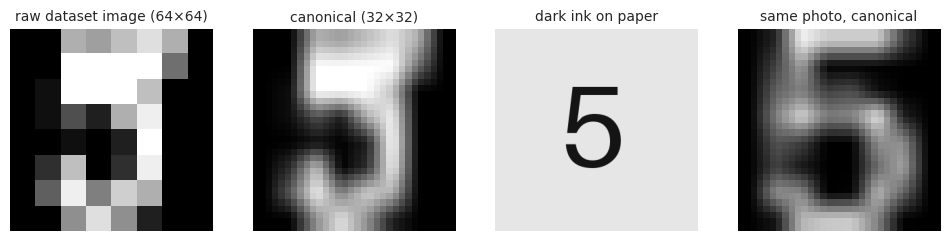

In [9]:
raw = sorted((prep.RAW_DIR / "train" / "5").iterdir())[0]
paper = Image.new("L", (300, 300), 230)
from PIL import ImageDraw, ImageFont
ImageDraw.Draw(paper).text((95, 40), "5", fill=20, font=ImageFont.load_default(size=170))

fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a, img, t in zip(ax, [Image.open(raw), prep.canonicalize(raw), paper, prep.canonicalize(paper)],
                     ["raw dataset image (64×64)", "canonical (32×32)", "dark ink on paper", "same photo, canonical"]):
    a.imshow(img, cmap="gray", vmin=0, vmax=255); a.set_title(t, fontsize=10); a.axis("off")
plt.show()

In [10]:
train_ds, val_ds, class_names = prep.load_datasets()
test_ds = prep.load_test_dataset(class_names=class_names)
x, y = next(iter(train_ds))
print("classes:", class_names)
print("batch:", x.shape, x.dtype, "| pixel range:", float(tf.reduce_min(x)), "to", float(tf.reduce_max(x)))

Found 1437 files belonging to 10 classes.
Using 1150 files for training.
Found 1437 files belonging to 10 classes.
Using 287 files for validation.
Found 360 files belonging to 10 classes.
classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
batch: (32, 32, 32, 1) <dtype: 'float32'> | pixel range: 0.0 to 255.0


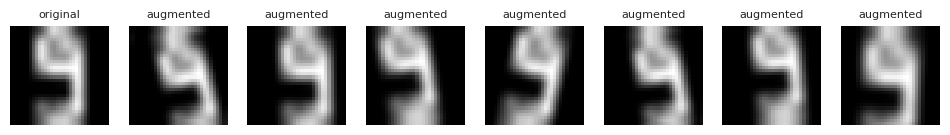

In [11]:
aug = prep.augmentation_layer()
plt.figure(figsize=(12, 2.4))
for i in range(8):
    plt.subplot(1, 8, i + 1)
    img = x[:1] if i == 0 else aug(x[:1], training=True)
    plt.imshow(img[0, :, :, 0], cmap="gray"); plt.axis("off"); plt.title("original" if i == 0 else "augmented", fontsize=8)
plt.show()

## 4. Model creation

A small convolutional network:

```
input 32×32×1 → augmentation → rescale to 0–1
→ [conv 32 → batch-norm → conv 32 → max-pool → dropout 0.25]
→ [conv 64 → batch-norm → conv 64 → max-pool → dropout 0.25]
→ flatten → dense 128 (ReLU, L2) → dropout 0.4 → softmax over 10 digits
```

- **Convolutions** learn local stroke patterns (curves, corners, endings) wherever they appear.
- **Batch normalisation** stabilises and speeds up training.
- **Dropout, L2 and augmentation**: three kinds of regularisation, needed with only ~1,150 training images.
- **Adam** (learning rate 0.001), **early stopping** on validation loss with best weights restored, and
  **ReduceLROnPlateau** to halve the learning rate when progress stalls.

In [12]:
model = mdl.build_model(len(class_names))
model.summary()

Model: "digit_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ scale_0_1 (Rescaling)           │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ digit (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 591,082 (2.25 MB)

 Trainable params: 590,890 (2.25 MB)

 Non-trainable params: 192 (768.00 B)

## 5. Training

In [13]:
history = model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=mdl.get_callbacks(), verbose=2)
history = mdl.history_dict(history)

Epoch 1/40


/workspaces/Digit-Classifier-MLOps-Pipeline/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-11-25 12:40:06.576058: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 23592960 exceeds 10% of free system memory.
2026-11-25 12:40:06.619422: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 21528576 exceeds 10% of free system memory.
2026-11-25 12:40:06.619702: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 21528576 exceeds 10% of free system memory.
2026-11-25 12:40:06.636874: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:83] Allocation of 28311552 exceeds 10% of free system memory.
2026-11-25 12:40:06.781124: W 

36/36 - 10s - 270ms/step - accuracy: 0.1704 - loss: 2.9134 - val_accuracy: 0.2195 - val_loss: 2.3070 - learning_rate: 0.0010
Epoch 2/40
36/36 - 7s - 206ms/step - accuracy: 0.2948 - loss: 1.9225 - val_accuracy: 0.2613 - val_loss: 2.2830 - learning_rate: 0.0010
Epoch 3/40
36/36 - 5s - 140ms/step - accuracy: 0.3765 - loss: 1.6775 - val_accuracy: 0.1603 - val_loss: 2.2534 - learning_rate: 0.0010
Epoch 4/40
36/36 - 4s - 118ms/step - accuracy: 0.4548 - loss: 1.4967 - val_accuracy: 0.2892 - val_loss: 2.2468 - learning_rate: 0.0010
Epoch 5/40
36/36 - 4s - 114ms/step - accuracy: 0.5209 - loss: 1.3557 - val_accuracy: 0.3484 - val_loss: 2.1752 - learning_rate: 0.0010
Epoch 6/40
36/36 - 4s - 112ms/step - accuracy: 0.5991 - loss: 1.1428 - val_accuracy: 0.4564 - val_loss: 2.0656 - learning_rate: 0.0010
Epoch 7/40
36/36 - 4s - 116ms/step - accuracy: 0.5896 - loss: 1.1253 - val_accuracy: 0.4181 - val_loss: 1.9423 - learning_rate: 0.0010
Epoch 8/40
36/36 - 5s - 135ms/step - accuracy: 0.6730 - loss: 0.9

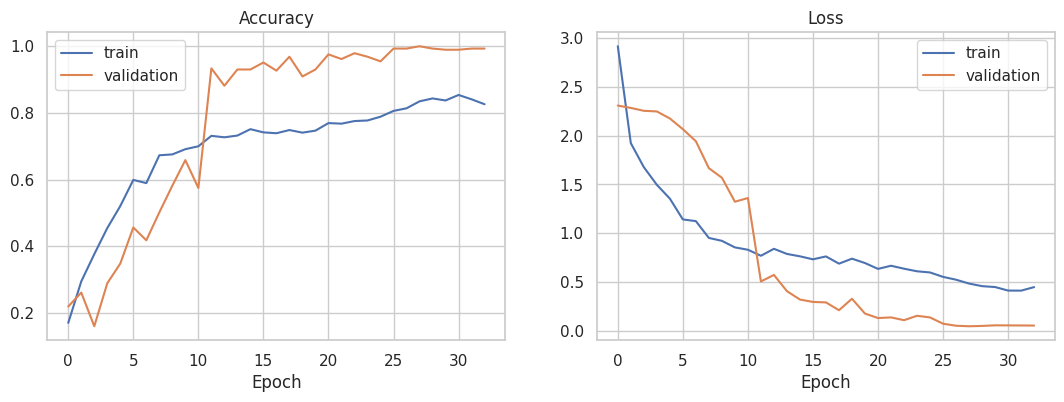

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, a in (("accuracy", ax[0]), ("loss", ax[1])):
    a.plot(history[k], label="train"); a.plot(history["val_" + k], label="validation")
    a.set(title=k.title(), xlabel="Epoch"); a.legend()
plt.show()

**Reading the curves.** Both accuracy curves rise and both loss curves fall steadily, so the model learned without overfitting. Validation is unstable for the first 10 epochs, while batch normalisation is still settling. Around epoch 11 validation accuracy jumps from about 0.58 to 0.93, and by epoch 25 it levels off near 0.99, with validation loss close to 0.05.

Validation accuracy ends above training accuracy (about 0.99 against 0.84). That is expected: dropout and augmentation make training harder on purpose and are switched off during validation. Early stopping ended training at around epoch 32, once validation loss stopped improving, and restored the best weights.

## 6. Model testing

On the 360 held-out test images:

- **Accuracy**: share classified correctly.
- **Precision** per digit: when the model says "3", how often it is a 3.
- **Recall** per digit: of all real 3s, how many it finds.
- **F1**: harmonic mean of precision and recall, macro (each digit equal) and weighted.
- **Log loss**: punishes confident mistakes, so it measures how trustworthy the probabilities are.
- **ROC-AUC (one-vs-rest)**: how well each digit is ranked above the others.
- **Confusion matrix**: which digits get mixed up.

In [15]:
metrics = mdl.evaluate_model(model, test_ds, class_names)
pd.Series({k: round(v, 4) for k, v in metrics.items() if isinstance(v, float)}, name="test set").to_frame()

2026-11-25 12:42:39.556049: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


,test set
accuracy,0.9944
precision_macro,0.9947
recall_macro,0.9943
f1_macro,0.9944
precision_weighted,0.9947
recall_weighted,0.9944
f1_weighted,0.9944
log_loss,0.0457
roc_auc_ovr,0.9999


In [16]:
pd.DataFrame(metrics["per_class"]).T.round(3)

,precision,recall,f1-score,support
0,1.000,1.000,1.000,36.000
1,0.947,1.000,0.973,36.000
2,1.000,1.000,1.000,35.000
3,1.000,1.000,1.000,37.000
4,1.000,1.000,1.000,36.000
5,1.000,1.000,1.000,37.000
6,1.000,1.000,1.000,36.000
7,1.000,1.000,1.000,36.000
8,1.000,0.943,0.971,35.000
9,1.000,1.000,1.000,36.000


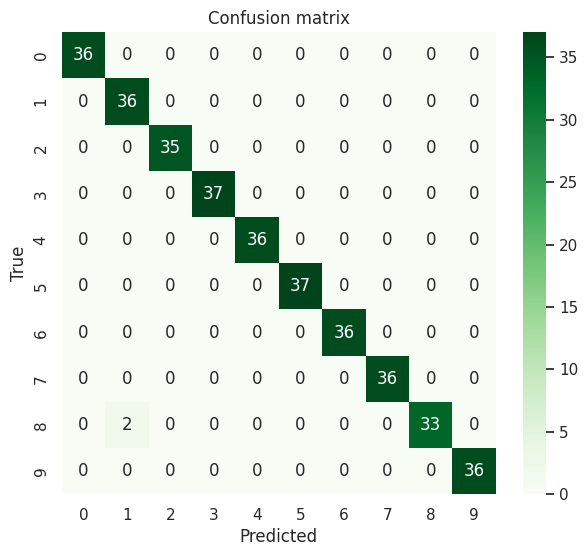

In [17]:
cm = np.array(metrics["confusion_matrix"])
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.show()

2026-11-25 12:42:41.116147: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


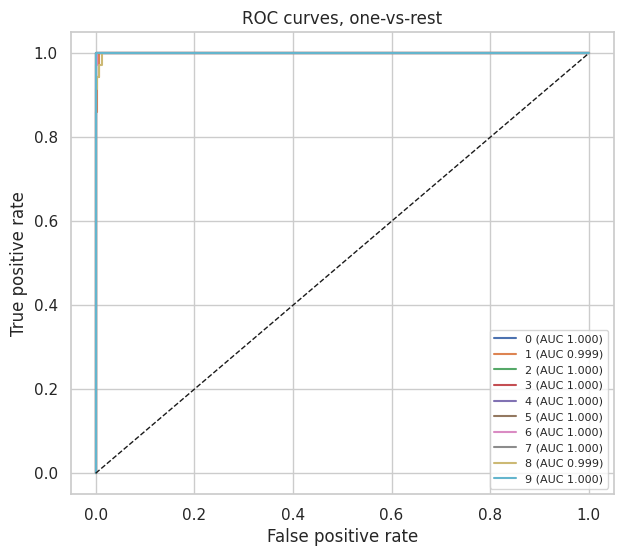

In [18]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
y_true, y_prob = mdl.predict_dataset(model, test_ds)
y_bin = label_binarize(y_true, classes=range(10))
plt.figure(figsize=(7, 6))
for i, c in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, label=f"{c} (AUC {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves, one-vs-rest"); plt.legend(fontsize=8); plt.show()

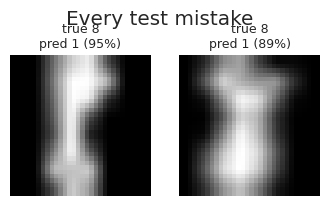

In [19]:
y_pred = y_prob.argmax(1)
test_files = [f for c in class_names for f in sorted((config.TEST_DIR / c).iterdir())]
wrong = np.where(y_pred != y_true)[0]
plt.figure(figsize=(2 * len(wrong), 2.4))
for k, i in enumerate(wrong):
    plt.subplot(1, len(wrong), k + 1); plt.imshow(Image.open(test_files[i]), cmap="gray"); plt.axis("off")
    plt.title(f"true {class_names[y_true[i]]}\npred {class_names[y_pred[i]]} ({y_prob[i].max():.0%})", fontsize=9)
plt.suptitle("Every test mistake"); plt.show()

**Conclusion.** The model classified 358 of 360 test images correctly, for 99.4% accuracy. Eight of the ten digits were perfect, and ROC-AUC is 1.000 for every digit except 1 and 8 (0.999).

Both mistakes are the same confusion: an 8 predicted as a 1, with 95% and 89% confidence. That gives digit 8 the lowest recall (33/35, 94%) and digit 1 the lowest precision (36/38, 95%).

The errors match the feature analysis. These two 8s are very thin and narrow, and 8 and 1 were the two narrowest, most variable digits in the width plot. Their loops are squashed almost into a straight line, so they look like a 1.

The confidence on these errors shows the model can be confidently wrong on unusual handwriting. Adding more narrow, compressed 8s through retraining would be the most direct improvement.

In [20]:
version = mdl.save_model(model, class_names, metrics, history, trigger="initial: notebook")
print("Saved", config.MODEL_PATH, "as version", version)

Saved /workspaces/Digit-Classifier-MLOps-Pipeline/models/digit_cnn.h5 as version 1


## 7. Prediction functions

`src/prediction.py` is what the API calls: it canonicalizes the image and returns the digit, the confidence and every class probability.

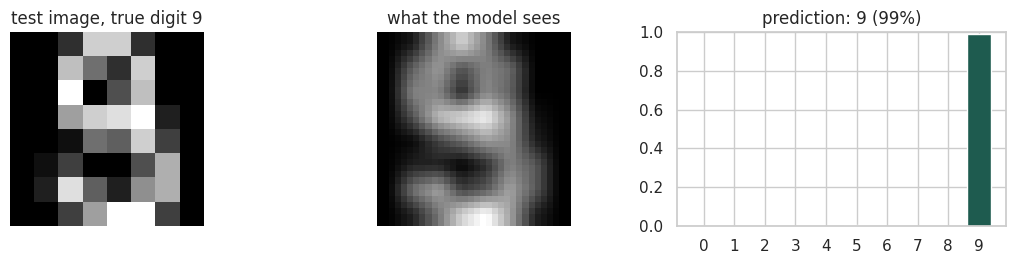

{'label': '9',
 'confidence': 0.9937551021575928,
 'probabilities': {'0': 2.9574252380371036e-08,
  '1': 2.1935724703325832e-07,
  '2': 5.228693589209854e-10,
  '3': 0.0013332628877833486,
  '4': 1.195309007329115e-08,
  '5': 0.004284604452550411,
  '6': 7.917125982581652e-11,
  '7': 1.165199137176387e-08,
  '8': 0.0006267232238315046,
  '9': 0.9937551021575928},
 'model_version': 1,
 'inference_ms': 22.87}

In [21]:
from src.prediction import Predictor
predictor = Predictor()

def show_prediction(image, title=""):
    r = predictor.predict(image)
    fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
    ax[0].imshow(Image.open(image) if isinstance(image, (str, Path)) else image, cmap="gray"); ax[0].set_title(title or "input"); ax[0].axis("off")
    ax[1].imshow(prep.canonicalize(image), cmap="gray"); ax[1].set_title("what the model sees"); ax[1].axis("off")
    ax[2].bar(list(r["probabilities"]), list(r["probabilities"].values()), color="#1E5B4F"); ax[2].set_ylim(0, 1)
    ax[2].set_title(f"prediction: {r['label']} ({r['confidence']:.0%})"); plt.tight_layout(); plt.show()
    return r

sample = random.choice(sorted((prep.RAW_DIR / "test").glob("*/*.png")))
show_prediction(sample, f"test image, true digit {sample.parent.name}")

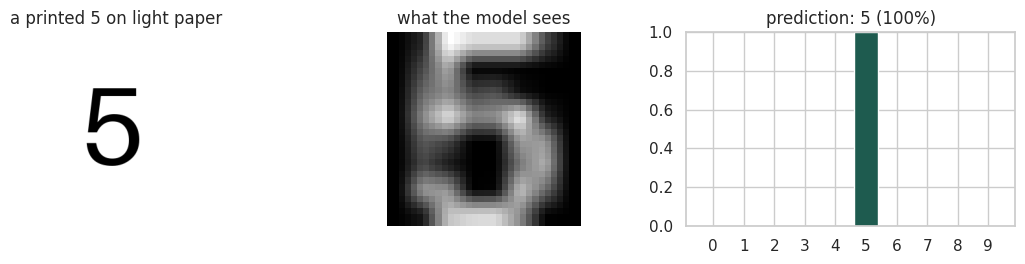

{'label': '5',
 'confidence': 0.9999953508377075,
 'probabilities': {'0': 4.370901649508596e-07,
  '1': 2.0055489387271752e-12,
  '2': 1.5618498623860076e-18,
  '3': 1.8104868715340672e-09,
  '4': 3.5381955143520827e-09,
  '5': 0.9999953508377075,
  '6': 3.1489133078821396e-08,
  '7': 3.762343908642052e-11,
  '8': 7.566229309752259e-10,
  '9': 4.204314791422803e-06},
 'model_version': 1,
 'inference_ms': 23.8}

In [22]:
buf = io.BytesIO(); paper.save(buf, "PNG")
show_prediction(Image.open(buf), "a printed 5 on light paper")

## 8. Retraining

How retraining works in production (`mdl.retrain`):

1. Users upload labelled digits (dashboard or `POST /upload`). Each image is canonicalized and saved to `data/uploads/<digit>/`.
2. **Trigger:** the *Retrain model* button, or automatically once `RETRAIN_THRESHOLD` (50) images are waiting.
3. Uploads move into `data/train` (20% into `data/test` so evaluation covers the new data).
4. The current model's weights are copied into a fresh network and training continues at a lower learning rate (warm start).
5. **Champion vs challenger:** old and new model are scored on the same test set; the new one goes live only if
   accuracy does not drop by more than 1%. The old file is archived in `models/archive/`.
6. Every API container notices the new model file and reloads it.

Here we simulate users uploading their own digits by drawing new ones with different fonts.
(In a real project these would be photos of handwritten digits.)

In [23]:
for d in range(10):
    for size in (120, 150, 180):
        img = Image.new("L", (260, 260), 235)
        ImageDraw.Draw(img).text((70, 20), str(d), fill=15, font=ImageFont.load_default(size=size))
        buf = io.BytesIO(); img.save(buf, "PNG")
        prep.save_uploads([(f"{d}_{size}.png", buf.getvalue())], label=str(d))
print("Pending uploads:", prep.pending_upload_count(), "| auto-trigger fires:", mdl.should_retrain())

Pending uploads: 30 | auto-trigger fires: False


In [24]:
result = mdl.retrain(trigger="manual: notebook demo", epochs=5)
result

Found 1467 files belonging to 10 classes.
Using 1174 files for training.
Found 1467 files belonging to 10 classes.
Using 293 files for validation.
Found 360 files belonging to 10 classes.


Epoch 1/5


/workspaces/Digit-Classifier-MLOps-Pipeline/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


37/37 - 8s - 209ms/step - accuracy: 0.8220 - loss: 0.5158 - val_accuracy: 0.9829 - val_loss: 0.1046 - learning_rate: 3.0000e-04
Epoch 2/5
37/37 - 5s - 137ms/step - accuracy: 0.8254 - loss: 0.4750 - val_accuracy: 0.9932 - val_loss: 0.0501 - learning_rate: 3.0000e-04
Epoch 3/5
37/37 - 5s - 137ms/step - accuracy: 0.8560 - loss: 0.4147 - val_accuracy: 0.9863 - val_loss: 0.0621 - learning_rate: 3.0000e-04
Epoch 4/5
37/37 - 5s - 123ms/step - accuracy: 0.8578 - loss: 0.3931 - val_accuracy: 0.9932 - val_loss: 0.0384 - learning_rate: 3.0000e-04
Epoch 5/5
37/37 - 6s - 158ms/step - accuracy: 0.8433 - loss: 0.4279 - val_accuracy: 0.9966 - val_loss: 0.0444 - learning_rate: 3.0000e-04


2026-11-25 12:43:16.741469: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


{'trigger': 'manual: notebook demo',
 'new_images': {'6': 3,
  '4': 3,
  '9': 3,
  '5': 3,
  '2': 3,
  '0': 3,
  '1': 3,
  '8': 3,
  '7': 3,
  '3': 3},
 'promoted': True,
 'old_accuracy': 0.9944444444444445,
 'new_accuracy': 0.9888888888888889,
 'new_f1_macro': np.float64(0.9887256834634968),
 'duration_s': 33.9,
 'version': 2}

In [ ]:
pd.DataFrame(mdl.read_json(config.META_PATH)["versions"])

,version,trained_at,trigger,accuracy,f1_macro,n_train,new_images
0,1,2026-11-25T12:42:41+00:00,initial: notebook,0.994444,0.994356,1437,NaN
1,2,2026-11-25T12:43:16+00:00,manual: notebook demo,0.988889,0.988726,1467,30.0


Bad pipe message: %s [b' q=0.9, image/jxl, image/avif, image/webp, image/apng, */*; q=0.8, application/signed-exchange; v=b3; q=0.7', b'Host: localh']
Bad pipe message: %s [b't:41499\r\nUser-Agent: Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/1', b'.0.0.0 Safari/537.36\r\nAccept-Encoding: gzip, deflate']
Bad pipe message: %s [b'br, zstd\r\nAccept-Language: en-US, en; q=0.9']
Bad pipe message: %s [b'Cache-Contro']
Bad pipe message: %s [b' max-age=0\r\nCookie: _ga_FVWC4GKEYS=GS2.1.s1795198430$o1$g1$t1795200986$j59$l0$h0\r\nReferer: https://github.c']
Bad pipe message: %s [b'/\r\nX-Request-ID: 2561baefefb58a27c86267ac0fcf85ce\r\nX-Real-IP: 10.241.0.36\r\nX-Forwarded-Port: 443\r\nX-Forwarded-', b'heme: https\r\nX-Original-URI: /\r\nX-Scheme: https\r\nsec-fetch-site: cross-site\r\nsec-f', b'ch-mode: navigate\r\nsec-fetch-dest: document\r\nsec-ch-ua: "Chromium";v="158", "Not.A/Brand";v="24", "G']
Bad pipe message: %s [b'gle Chrome";v="158"\r\nsec-ch

## Summary

*Data:* 1,797 handwritten digits (8×8), balanced at about 144 per digit, with 1,437 used for training and 360 held out for testing.

*Features:* Width only separates digit 1 (and partly 8), and ink amount barely differs between digits. Top-heaviness and the average-digit images show which digits are easy to separate (6 vs 9) and which are written in many styles (1, 4, 7). So the model has to learn shape, which is why a CNN suits this data.

*Preprocessing:* One canonicalize() step crops, centres and resizes every image to 32×32, so training data, uploads and predictions always look the same. Augmentation (small rotations, shifts and zooms) reduces overfitting.

*Training:* The small CNN trained for about 32 epochs before early stopping, reaching about 99% validation accuracy with no sign of overfitting.

*Testing:* 358 of 360 test images were correct (99.4% accuracy), with ROC-AUC of about 1.000 for every digit. The only mistakes were two very narrow 8s predicted as 1, which matches the width analysis.

*Prediction:* A test 9 was read correctly with 99% confidence. A printed 5 on light paper was read with 100% confidence, showing that preprocessing lets the model handle images that look nothing like the dataset.

*Retraining:* New labelled images can be uploaded and the model retrained, either with a button or automatically after 50 uploads. A new model only replaces the current one if it scores at least as well on the test set..